In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data_loader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


## 1. Chargement et aperçu initial

In [2]:
df = data_loader.load_raw_data()
print(f"Dimensions : {df.shape}")
df.head()


2026-10-09 22:34:45,745 [INFO] Chargement du dataset local : C:\Users\HP\Desktop\projet-IA-DS-2026-01-Moussaoui-Lina\data\raw\creditcard.csv
2026-10-09 22:34:51,573 [INFO] Dataset chargé : 284807 lignes, 31 colonnes


Dimensions : (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


## 2. Analyse orientée déséquilibre — distribution de la variable cible

C'est le point central de l'EDA imposé par le cahier des charges : le déséquilibre
des classes conditionne tous les choix méthodologiques ultérieurs (métriques,
stratégies de rééquilibrage, seuil de décision).

Effectifs par classe :
Class
0    284315
1       492
Name: count, dtype: int64

Proportions (%) :
Class
0    99.827
1     0.173
Name: proportion, dtype: float64


2026-10-09 22:34:54,472 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-09 22:34:55,065 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


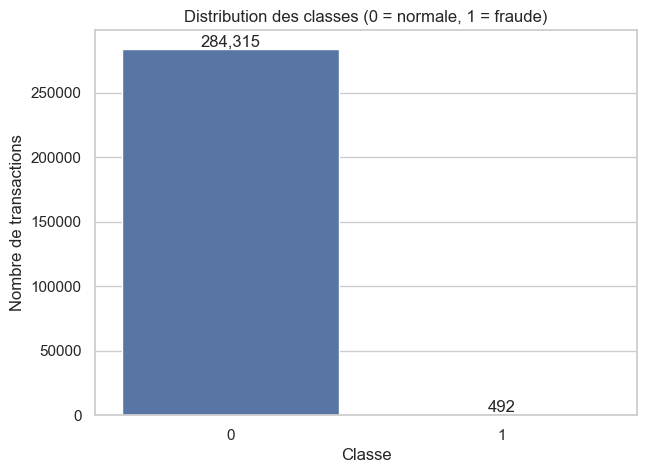

In [5]:
counts = df[config.TARGET_COL].value_counts()
proportions = df[config.TARGET_COL].value_counts(normalize=True) * 100

print("Effectifs par classe :")
print(counts)
print("\nProportions (%) :")
print(proportions.round(3))

plt.figure(figsize=(7, 5))
sns.countplot(x=config.TARGET_COL, data=df)
plt.title("Distribution des classes (0 = normale, 1 = fraude)")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")
for i, v in enumerate(counts.sort_index()):
    plt.text(i, v + 2000, f"{v:,}", ha="center")
plt.savefig(config.FIGURES_DIR / "distribution_classes.png", bbox_inches="tight", dpi=150)
plt.show()


**Constat** : le taux de positifs est de 0,17 %, largement inférieur au seuil de
5 % exigé par le cahier des charges pour qualifier le problème de "données
déséquilibrées". Ce constat justifie à lui seul le rejet de l'accuracy comme
métrique de sélection de modèle (un classifieur trivial "toujours non-fraude"
atteindrait ~99,8 % d'accuracy sans aucune utilité métier).

## 3. Montant des transactions par classe

2026-10-09 22:34:57,052 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-09 22:34:57,671 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


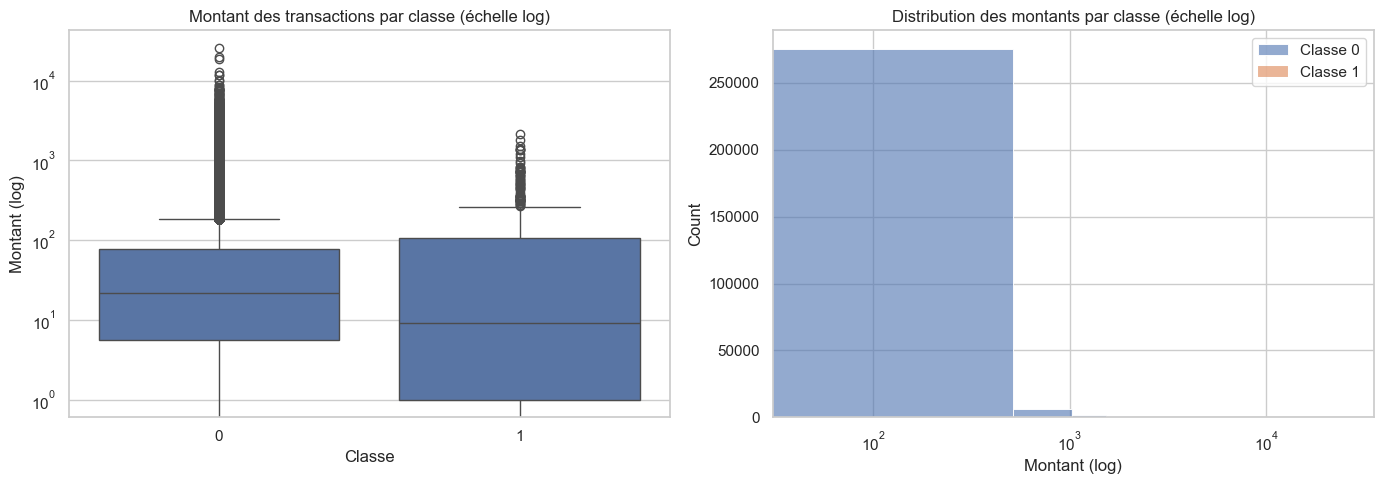

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x=config.TARGET_COL, y=config.AMOUNT_COL, data=df, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Montant des transactions par classe (échelle log)")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Montant (log)")

for class_val in [0, 1]:
    sns.histplot(df[df[config.TARGET_COL] == class_val][config.AMOUNT_COL],
                 label=f"Classe {class_val}", bins=50, ax=axes[1], alpha=0.6)
axes[1].set_xscale("log")
axes[1].set_title("Distribution des montants par classe (échelle log)")
axes[1].set_xlabel("Montant (log)")
axes[1].legend()

plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "amount_by_class.png", bbox_inches="tight", dpi=150)
plt.show()


**Constat** : les montants des transactions frauduleuses ont une distribution
différente de celle des transactions légitimes, avec une médiane plus élevée mais
une variance importante. Cette information sera cruciale pour l'analyse d'erreurs
(faux négatifs à montant élevé) au chapitre 5 du rapport.

## 4. Structure temporelle (`Time`)

Le dataset possède un ordre temporel implicite. Cette section motive le choix,
fait dans `notebooks/02_preparation.ipynb`, d'un **découpage temporel strict**
plutôt qu'aléatoire.

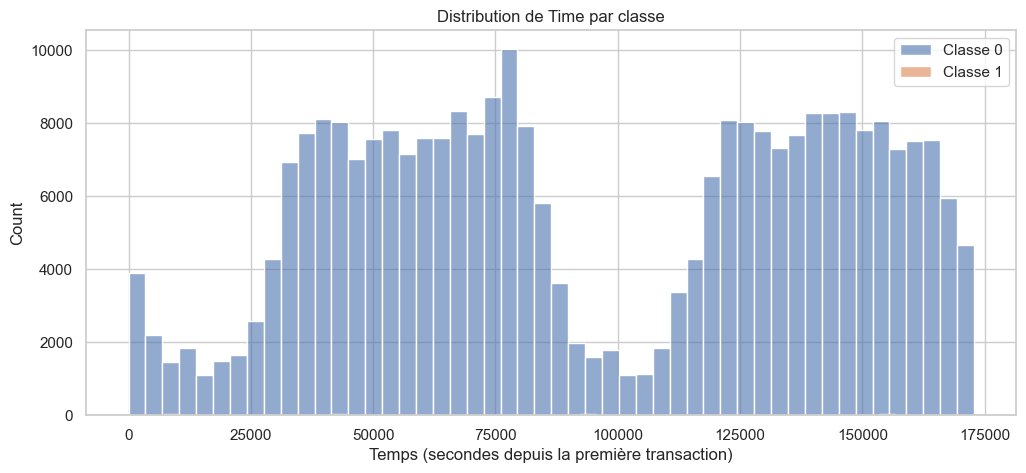

Durée totale couverte : 48.0 heures (~2.0 jours)


In [7]:
plt.figure(figsize=(12, 5))
for class_val in [0, 1]:
    sns.histplot(df[df[config.TARGET_COL] == class_val][config.TIME_COL],
                 label=f"Classe {class_val}", bins=50, alpha=0.6)
plt.title("Distribution de Time par classe")
plt.xlabel("Temps (secondes depuis la première transaction)")
plt.legend()
plt.savefig(config.FIGURES_DIR / "time_distribution.png", bbox_inches="tight", dpi=150)
plt.show()

print(f"Durée totale couverte : {df[config.TIME_COL].max() / 3600:.1f} heures "
      f"(~{df[config.TIME_COL].max() / 86400:.1f} jours)")


**Constat** : les transactions frauduleuses sont réparties sur toute la période,
sans pic temporel évident isolé. `Time` seul n'est pas fortement discriminant,
mais conditionne néanmoins le **protocole d'évaluation** (découpage temporel
obligatoire, cf. points de vigilance du cahier des charges).

## 5. Matrice de corrélation

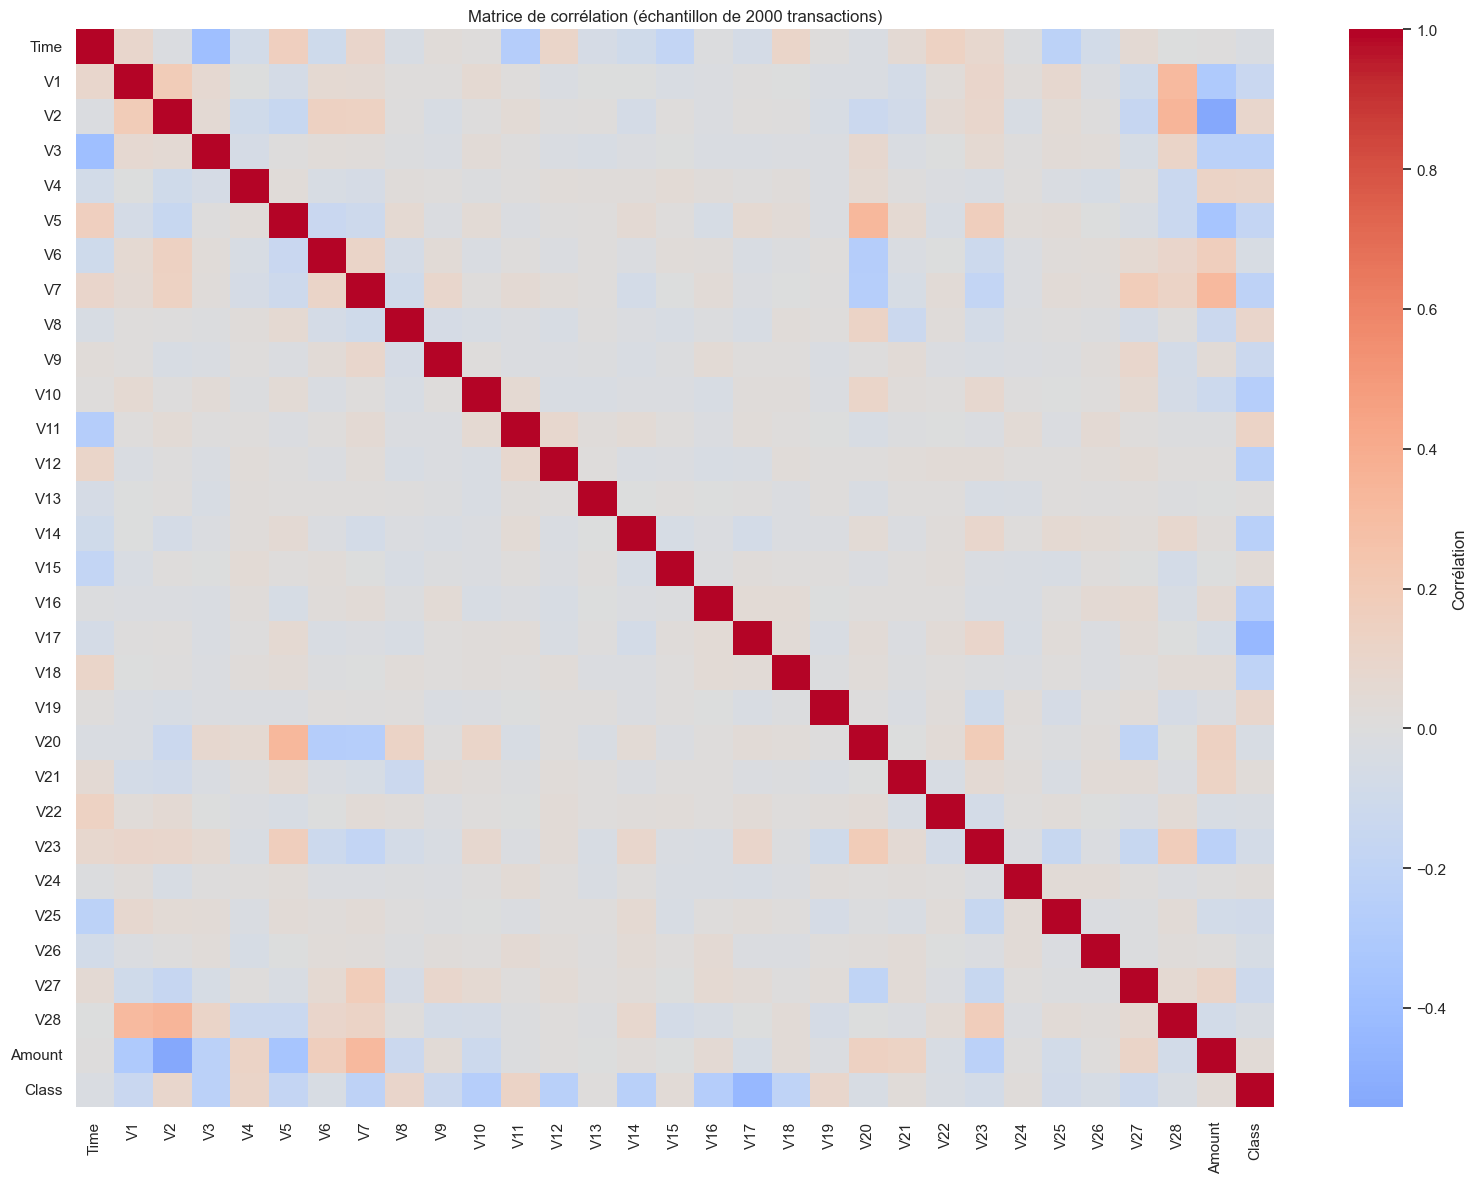

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64

In [8]:
sample_corr = df.sample(2000, random_state=config.RANDOM_STATE).corr()

plt.figure(figsize=(16, 12))
sns.heatmap(sample_corr, cmap="coolwarm", center=0, cbar_kws={"label": "Corrélation"})
plt.title("Matrice de corrélation (échantillon de 2000 transactions)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "correlation_matrix.png", bbox_inches="tight", dpi=150)
plt.show()

# Corrélation de chaque variable avec la cible, triée par valeur absolue
corr_with_target = df.corr()[config.TARGET_COL].drop(config.TARGET_COL)
corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index).head(10)


**Constat** : conformément à l'attendu d'une PCA, les variables V1 à V28 sont peu
corrélées entre elles. Certaines (V17, V14, V12, V10, V11, V4...) présentent en
revanche une corrélation notable avec `Class` et seront probablement importantes
pour les modèles (à confirmer par l'analyse SHAP au notebook 03).

## 6. Qualité des données (aperçu)

Le nettoyage complet est réalisé dans `notebooks/02_preparation.ipynb` /
`src/preprocessing.py`. On vérifie ici, à titre exploratoire, les valeurs
manquantes et les doublons.

In [9]:
print(f"Valeurs manquantes totales : {df.isnull().sum().sum()}")
print(f"Doublons exacts : {df.duplicated().sum()} lignes sur {len(df)}")


Valeurs manquantes totales : 0
Doublons exacts : 1081 lignes sur 284807


## 7. Synthèse de l'EDA

1. **Déséquilibre extrême** (0,17 % de fraudes) → métriques adaptées obligatoires
   (PR-AUC en priorité), accuracy écartée.
2. **Montant** : distribution différente entre fraude et non-fraude, à exploiter
   dans l'analyse d'erreurs.
3. **Structure temporelle** présente → découpage temporel obligatoire (S1).
4. **Variables V** peu corrélées entre elles (effet PCA), certaines corrélées à
   la cible.
5. **Qualité** : dataset globalement propre, doublons à traiter en S1/S2.

➡️ Suite du pipeline : `notebooks/02_preparation.ipynb`.